In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
print("PyTorch Version:", torch.__version__)
print("NumPy Version:", np.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch Version: 2.14.1+cpu
NumPy Version: 2.4.6
Device: CPU


## 1. Loading Fashion-MNIST Dataset

Fashion-MNIST is a dataset of grayscale clothing images.

It contains 10 categories:
T-shirt, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag and Ankle Boot.

Each image has dimensions of 28 × 28 pixels.

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Image shape:", train_dataset[0][0].shape)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.2MB/s]

Training samples: 60000
Testing samples: 10000
Image shape: torch.Size([1, 28, 28])


## 2. Visualising Fashion-MNIST Images

Display sample clothing images with their corresponding category names to understand the dataset.

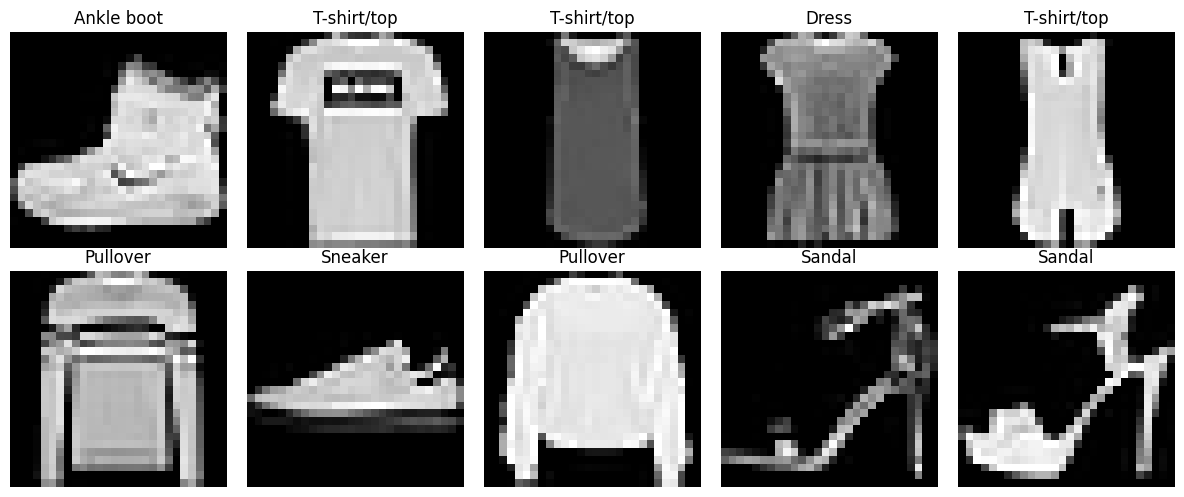

In [ ]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Preparing Training, Validation and Testing Data

Split the original training dataset into training and validation datasets.

- Training: 50,000 images
- Validation: 10,000 images
- Testing: 10,000 images

Normalize image values to improve model training.

In [ ]:
from torch.utils.data import random_split

train_size = 50000
val_size = 10000

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Testing samples:", len(test_dataset))

Training samples: 50000
Validation samples: 10000
Testing samples: 10000


## 4. Image Normalization and DataLoaders

Normalize Fashion-MNIST images using the dataset mean and standard deviation.

Create DataLoaders to load images in batches of 64.

Shuffle the training data to improve learning.

In [ ]:
from torch.utils.data import DataLoader
from torchvision import transforms

normalization = transforms.Normalize(
    (0.2860,),
    (0.3530,)
)

train_dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    normalization
])

test_dataset.transform = transforms.Compose([
    transforms.ToTensor(),
    normalization
])

batch_size = 64

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_subset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

images, labels = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Normalized pixel range:", images.min().item(), "to", images.max().item())

Training batches: 782
Validation batches: 157
Testing batches: 157
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Normalized pixel range: -0.8101983666419983 to 2.022662878036499


## 5. Building a Convolutional Neural Network (CNN)

Build a CNN with two convolutional layers, ReLU activation, max pooling and fully connected layers.

The network classifies Fashion-MNIST images into 10 clothing categories.

In [ ]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x


cnn_model = FashionCNN()

print(cnn_model)

FashionCNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 6. Building a Fully Connected Baseline Model

Build a fully connected neural network to classify Fashion-MNIST images.

The model uses flattened image pixels and two linear layers.
This model will serve as a baseline for comparison with the CNN.

In [ ]:
class FashionANN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


ann_model = FashionANN()

print(ann_model)

FashionANN(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 7. Model Configuration

Configure both CNN and ANN using CrossEntropyLoss and Adam optimizer.

Use the same learning rate and number of epochs for a fair comparison.

In [ ]:
criterion = nn.CrossEntropyLoss()

cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)
ann_optimizer = optim.Adam(ann_model.parameters(), lr=0.001)

epochs = 5

print("Loss Function:", criterion)
print("CNN Optimizer:", cnn_optimizer)
print("ANN Optimizer:", ann_optimizer)
print("Epochs:", epochs)

Loss Function: CrossEntropyLoss()
CNN Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
ANN Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Epochs: 5


## 8. Training CNN and ANN Models

Train both models using the Fashion-MNIST training dataset.

Record training loss, training accuracy, validation loss and validation accuracy after every epoch.

Use the validation dataset to monitor model performance.

In [ ]:
def train_model(model, optimizer, model_name):
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):

        model.train()
        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        model.eval()
        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss / val_total
        val_accuracy = 100 * val_correct / val_total

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"{model_name} | Epoch [{epoch+1}/{epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Accuracy: {train_accuracy:.2f}% "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Accuracy: {val_accuracy:.2f}%"
        )

    return history

In [ ]:
ann_history = train_model(
    ann_model,
    ann_optimizer,
    "ANN"
)

ANN | Epoch [1/5] | Train Loss: 0.4785 | Train Accuracy: 82.85% | Val Loss: 0.3923 | Val Accuracy: 85.49%
ANN | Epoch [2/5] | Train Loss: 0.3643 | Train Accuracy: 86.71% | Val Loss: 0.3521 | Val Accuracy: 87.02%
ANN | Epoch [3/5] | Train Loss: 0.3259 | Train Accuracy: 87.96% | Val Loss: 0.3372 | Val Accuracy: 87.70%
ANN | Epoch [4/5] | Train Loss: 0.3005 | Train Accuracy: 88.93% | Val Loss: 0.3370 | Val Accuracy: 87.61%
ANN | Epoch [5/5] | Train Loss: 0.2813 | Train Accuracy: 89.64% | Val Loss: 0.3145 | Val Accuracy: 88.74%


In [ ]:
cnn_history = train_model(
    cnn_model,
    cnn_optimizer,
    "CNN"
)

CNN | Epoch [1/5] | Train Loss: 0.4374 | Train Accuracy: 84.15% | Val Loss: 0.3303 | Val Accuracy: 88.25%
CNN | Epoch [2/5] | Train Loss: 0.2855 | Train Accuracy: 89.60% | Val Loss: 0.3008 | Val Accuracy: 89.36%
CNN | Epoch [3/5] | Train Loss: 0.2425 | Train Accuracy: 90.98% | Val Loss: 0.2482 | Val Accuracy: 91.16%
CNN | Epoch [4/5] | Train Loss: 0.2114 | Train Accuracy: 92.15% | Val Loss: 0.2546 | Val Accuracy: 90.77%
CNN | Epoch [5/5] | Train Loss: 0.1841 | Train Accuracy: 93.05% | Val Loss: 0.2354 | Val Accuracy: 91.50%


## 9. Training and Validation Curves

Visualize and compare the training loss, validation loss, training accuracy and validation accuracy of CNN and ANN models.

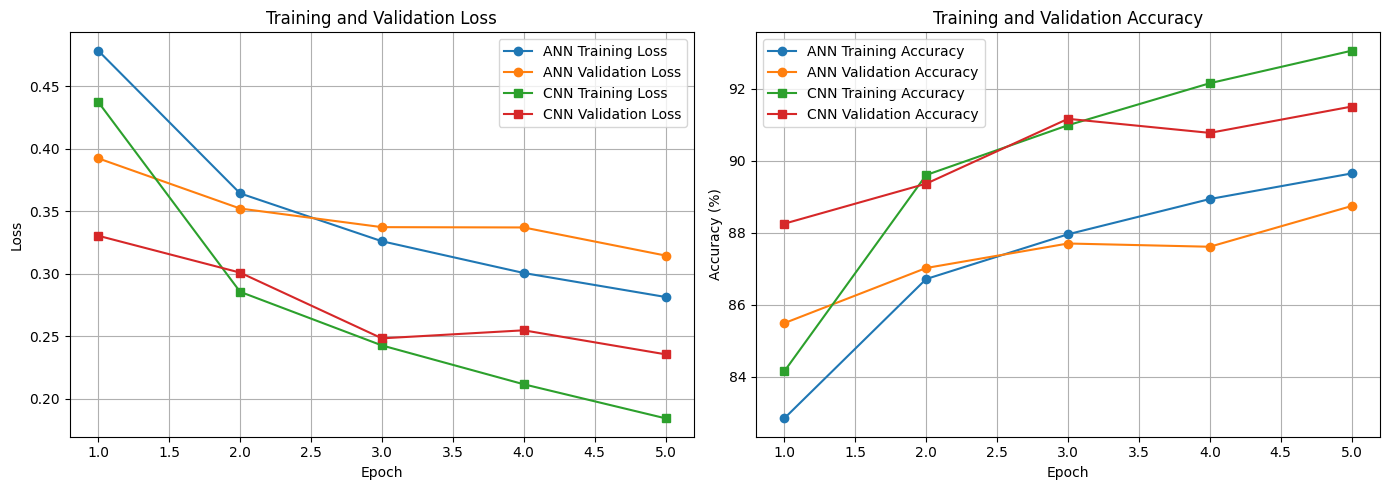

In [ ]:
epochs_range = range(1, epochs + 1)

plt.figure(figsize=(14, 5))

# Loss curves
plt.subplot(1, 2, 1)

plt.plot(epochs_range, ann_history["train_loss"], marker="o", label="ANN Training Loss")
plt.plot(epochs_range, ann_history["val_loss"], marker="o", label="ANN Validation Loss")
plt.plot(epochs_range, cnn_history["train_loss"], marker="s", label="CNN Training Loss")
plt.plot(epochs_range, cnn_history["val_loss"], marker="s", label="CNN Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

# Accuracy curves
plt.subplot(1, 2, 2)

plt.plot(epochs_range, ann_history["train_accuracy"], marker="o", label="ANN Training Accuracy")
plt.plot(epochs_range, ann_history["val_accuracy"], marker="o", label="ANN Validation Accuracy")
plt.plot(epochs_range, cnn_history["train_accuracy"], marker="s", label="CNN Training Accuracy")
plt.plot(epochs_range, cnn_history["val_accuracy"], marker="s", label="CNN Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## 10. Final Test Evaluation

Evaluate both ANN and CNN models using the unseen Fashion-MNIST test dataset and compare their accuracy.

In [ ]:
def evaluate_model(model, model_name):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total

    print(f"{model_name} Test Accuracy: {accuracy:.2f}%")

    return accuracy


ann_test_accuracy = evaluate_model(ann_model, "ANN")
cnn_test_accuracy = evaluate_model(cnn_model, "CNN")

ANN Test Accuracy: 87.34%
CNN Test Accuracy: 90.81%


## 11. CNN Misclassified Examples

Display five test images that the CNN model classified incorrectly.

Compare the actual clothing category with the predicted category.

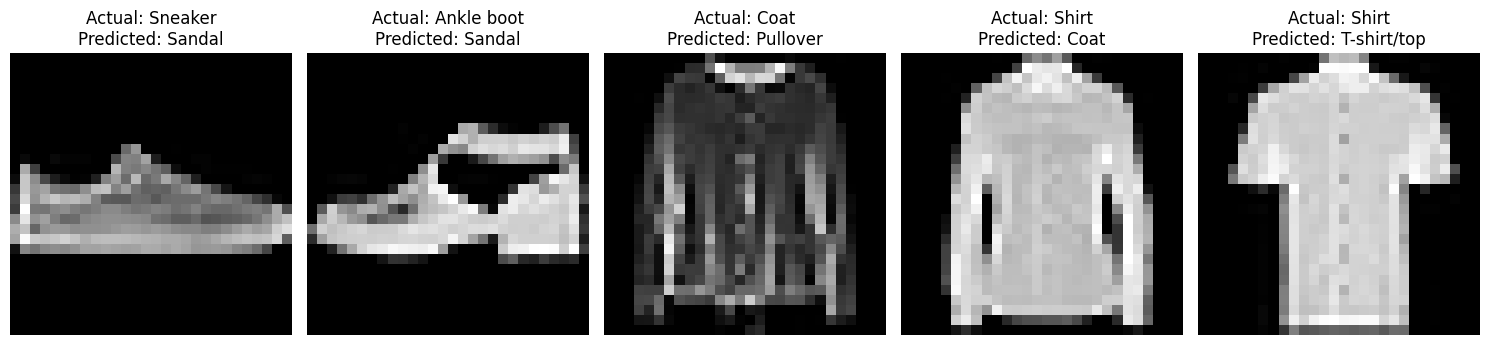

In [ ]:
cnn_model.eval()

wrong_images = []
wrong_labels = []
wrong_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        wrong_indices = (predictions != labels).nonzero(as_tuple=True)[0]

        for idx in wrong_indices:
            wrong_images.append(images[idx].squeeze().cpu())
            wrong_labels.append(labels[idx].item())
            wrong_predictions.append(predictions[idx].item())

            if len(wrong_images) == 5:
                break

        if len(wrong_images) == 5:
            break

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, ax in enumerate(axes):
    image = wrong_images[i] * 0.3530 + 0.2860

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"Actual: {class_names[wrong_labels[i]]}\n"
        f"Predicted: {class_names[wrong_predictions[i]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Error Analysis

The CNN model misclassified five test images.

The incorrect predictions were:

1. Sneaker predicted as Sandal.
2. Ankle boot predicted as Sandal.
3. Coat predicted as Pullover.
4. Shirt predicted as Coat.
5. Shirt predicted as T-shirt/top.

These errors may occur because some clothing categories have similar shapes and visual features. Fashion-MNIST images are small (28 × 28 pixels) and grayscale, which makes it difficult to distinguish certain details.

The model achieved 90.81% test accuracy, showing that it can correctly classify most clothing images, although some visually similar categories remain challenging.

## 12. Save the Trained CNN Model

Save the trained CNN model weights so that the model can be loaded and reused later without training again.

In [ ]:
torch.save(cnn_model.state_dict(), "fashion_cnn.pth")

print("CNN model saved successfully!")

CNN model saved successfully!


## 13. ANN vs CNN – Final Comparison

| Metric | ANN | CNN |
|---|---:|---:|
| Training Accuracy | 89.64% | 93.05% |
| Validation Accuracy | 88.74% | 91.50% |
| Test Accuracy | 87.34% | 90.81% |
| Training Loss | 0.2813 | 0.1841 |
| Validation Loss | 0.3145 | 0.2354 |

### Conclusion

In this assignment, we built and evaluated two deep learning models, ANN and CNN, using the Fashion-MNIST dataset.

The ANN achieved 87.34% test accuracy, whereas the CNN achieved 90.81%.

The CNN performed better because convolutional layers can identify important image features such as edges, shapes and patterns while preserving spatial information.

Therefore, CNN is more suitable for image classification tasks than the simple fully connected ANN used in this experiment.